# Stock Correlation Networks and Community Detection

**Dynamic Complex Networks — course project**

The idea here is simple: if two stocks tend to go up and down on the same days,
there is probably something connecting them. I take the daily returns of 33 large
US stocks between 2019 and 2023, measure the correlation between every pair, and
turn that into a network where an edge means "these two move together".

Then I run the Louvain algorithm on that network to see if it splits into groups,
and check whether those groups match the actual industry sectors.

What the notebook covers:

1. Loading prices and computing daily returns
2. Building the correlation network
3. Community detection with Louvain
4. How much the result depends on the threshold and the resolution parameter
5. Pearson vs Spearman correlation
6. Which stocks are the most central
7. Comparing the communities to real GICS sectors
8. Whether the structure is stable over time (rolling windows)

In [1]:
# If you are running this on Colab, uncomment the line below first.
# !pip install yfinance networkx python-louvain scikit-learn

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import community as community_louvain
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Louvain is random, so I fix a seed to get the same result on every run.
SEED = 42

DATA_FILE = "data/prices.csv"
FIGURE_DIR = "figures"

os.makedirs(FIGURE_DIR, exist_ok=True)

## 1. The data

33 stocks from 8 sectors, so that there is a chance of seeing more than one
group. The prices are adjusted closes, which means splits and dividends are
already taken into account.

I downloaded the prices once and saved them to `data/prices.csv`. The notebook
reads that file, and only falls back to downloading from Yahoo if the file is
missing. Without this the numbers would change every time someone re-runs the
notebook, which would make the results impossible to check.

In [2]:
tickers = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'NVDA', 'NFLX',
    'JPM', 'BAC', 'WFC', 'GS', 'MS', 'V', 'MA',
    'JNJ', 'PFE', 'MRK', 'UNH', 'ABBV',
    'XOM', 'CVX', 'COP', 'SLB',
    'WMT', 'PG', 'KO', 'PEP', 'HD', 'MCD',
    'BA', 'CAT', 'GE']

START_DATE = "2019-01-01"
END_DATE = "2024-01-01"

if os.path.exists(DATA_FILE):
    prices = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
    print("Prices loaded from", DATA_FILE)
else:
    import yfinance as yf

    data = yf.download(tickers, start=START_DATE, end=END_DATE, auto_adjust=True)
    prices = data["Close"].sort_index(axis=1)
    os.makedirs("data", exist_ok=True)
    prices.to_csv(DATA_FILE)
    print("Prices downloaded from Yahoo and saved to", DATA_FILE)

print("shape:", prices.shape)
print("period:", prices.index.min().date(), "to", prices.index.max().date())
print("missing prices:", int(prices.isna().sum().sum()))

prices.iloc[:5, :6]

Prices loaded from data/prices.csv
shape: (1258, 33)
period: 2019-01-02 to 2023-12-29
missing prices: 0


,AAPL,ABBV,AMZN,BA,BAC,CAT
Date,,,,,,
2019-01-02,37.436916,63.938934,76.956497,314.645142,20.731045,107.567749
2019-01-03,33.707924,61.832253,75.014000,302.100525,20.398817,103.422668
2019-01-04,35.146885,63.824280,78.769501,317.822571,21.246002,109.074272
2019-01-07,35.068653,64.755821,81.475502,318.823456,21.229391,109.142365
2019-01-08,35.737179,65.056778,82.829002,330.891876,21.187859,110.453125


## 2. Daily returns and the correlation matrix

I work with returns rather than prices. Two prices can look correlated just
because both of them drift upwards over five years, and that is not the kind of
relationship I am after. Returns remove most of that trend, so the correlation
says something about day-to-day co-movement instead.

In [3]:
returns = prices.pct_change().dropna()
corr_matrix = returns.corr()

print("trading days used:", len(returns))

# Quick sanity check on the correlation values.
pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
print("number of stock pairs:", len(pairs))
print("mean correlation:", round(pairs.mean(), 3))
print("min / max correlation:", round(pairs.min(), 3), "/", round(pairs.max(), 3))
print("negative correlations:", int((pairs < 0).sum()))

corr_matrix.iloc[:4, :4]

trading days used: 1257
number of stock pairs: 528
mean correlation: 0.417
min / max correlation: 0.098 / 0.913
negative correlations: 0


,AAPL,ABBV,AMZN,BA
AAPL,1.000000,0.337083,0.619210,0.416347
ABBV,0.337083,1.000000,0.196016,0.267619
AMZN,0.619210,0.196016,1.000000,0.280402
BA,0.416347,0.267619,0.280402,1.000000


## 3. Building the network

Every stock becomes a node. I add an edge between two stocks when the absolute
value of their correlation is above a threshold.

One detail that matters: I use the **absolute** correlation as the edge weight,
not the raw value. Modularity assumes positive weights, so a negative weight
would quietly produce a meaningless score. The signed value is still stored on
the edge under `correlation` in case it is needed later.

In [4]:
def build_graph(corr, threshold):
    """Build an undirected graph from a correlation matrix."""
    G = nx.Graph()
    G.add_nodes_from(corr.columns)

    names = list(corr.columns)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            value = corr.iloc[i, j]
            if abs(value) > threshold:
                G.add_edge(names[i], names[j],
                           weight=abs(value),
                           correlation=value)
    return G


threshold = 0.7
G = build_graph(corr_matrix, threshold)

print("threshold:", threshold)
print("number of nodes:", G.number_of_nodes())
print("number of edges:", G.number_of_edges())
print("density:", round(nx.density(G), 4))
print("isolated nodes:", len(list(nx.isolates(G))))
print("connected components:", nx.number_connected_components(G))

threshold: 0.7
number of nodes: 33
number of edges: 22
density: 0.0417
isolated nodes: 15
connected components: 20


In [5]:
def find_communities(G, resolution=1.0, seed=SEED):
    """Run Louvain and return the partition together with its modularity."""
    if G.number_of_edges() == 0:
        # No edges at all, so every stock is its own community.
        return {node: i for i, node in enumerate(G.nodes())}, 0.0

    partition = community_louvain.best_partition(
        G, weight="weight", resolution=resolution, random_state=seed)
    modularity = community_louvain.modularity(partition, G, weight="weight")
    return partition, modularity


def group_by_community(partition):
    """Turn {stock: community_id} into {community_id: [stocks]}."""
    groups = {}
    for node, com_id in partition.items():
        groups.setdefault(com_id, []).append(node)
    return groups


partition, modularity = find_communities(G)
groups = group_by_community(partition)

print("modularity:", round(modularity, 4))
print("number of communities:", len(groups))
print()

real_groups = {c: m for c, m in groups.items() if len(m) > 1}
alone = sorted(m[0] for m in groups.values() if len(m) == 1)

print("Communities with more than one stock:")
for com_id in sorted(real_groups):
    print("  ", sorted(real_groups[com_id]))

print()
print("Stocks that ended up alone (" + str(len(alone)) + "):")
print("  ", alone)

modularity: 0.6824
number of communities: 20

Communities with more than one stock:
   ['AAPL', 'GOOGL', 'MSFT', 'NVDA']
   ['COP', 'CVX', 'SLB', 'XOM']
   ['KO', 'PEP', 'PG']
   ['BAC', 'GS', 'JPM', 'MS', 'WFC']
   ['MA', 'V']

Stocks that ended up alone (15):
   ['ABBV', 'AMZN', 'BA', 'CAT', 'GE', 'HD', 'JNJ', 'MCD', 'META', 'MRK', 'NFLX', 'PFE', 'TSLA', 'UNH', 'WMT']


The groups that do come out look right: the big banks land together, the oil
companies land together, the mega-cap tech names land together, and the consumer
staples land together. So the method is picking up something real.

But I should not get excited about the modularity score. Most of the 33 stocks
end up alone in their own community, because at a threshold of 0.7 the network
only has a handful of edges. Modularity rewards a partition where there are few
edges between groups, and a network that is mostly empty satisfies that almost
by accident. A high score on a nearly empty graph does not mean the community
structure is strong.

That is the reason for the next section: instead of trusting one threshold, I
want to see how the picture changes when I vary it.

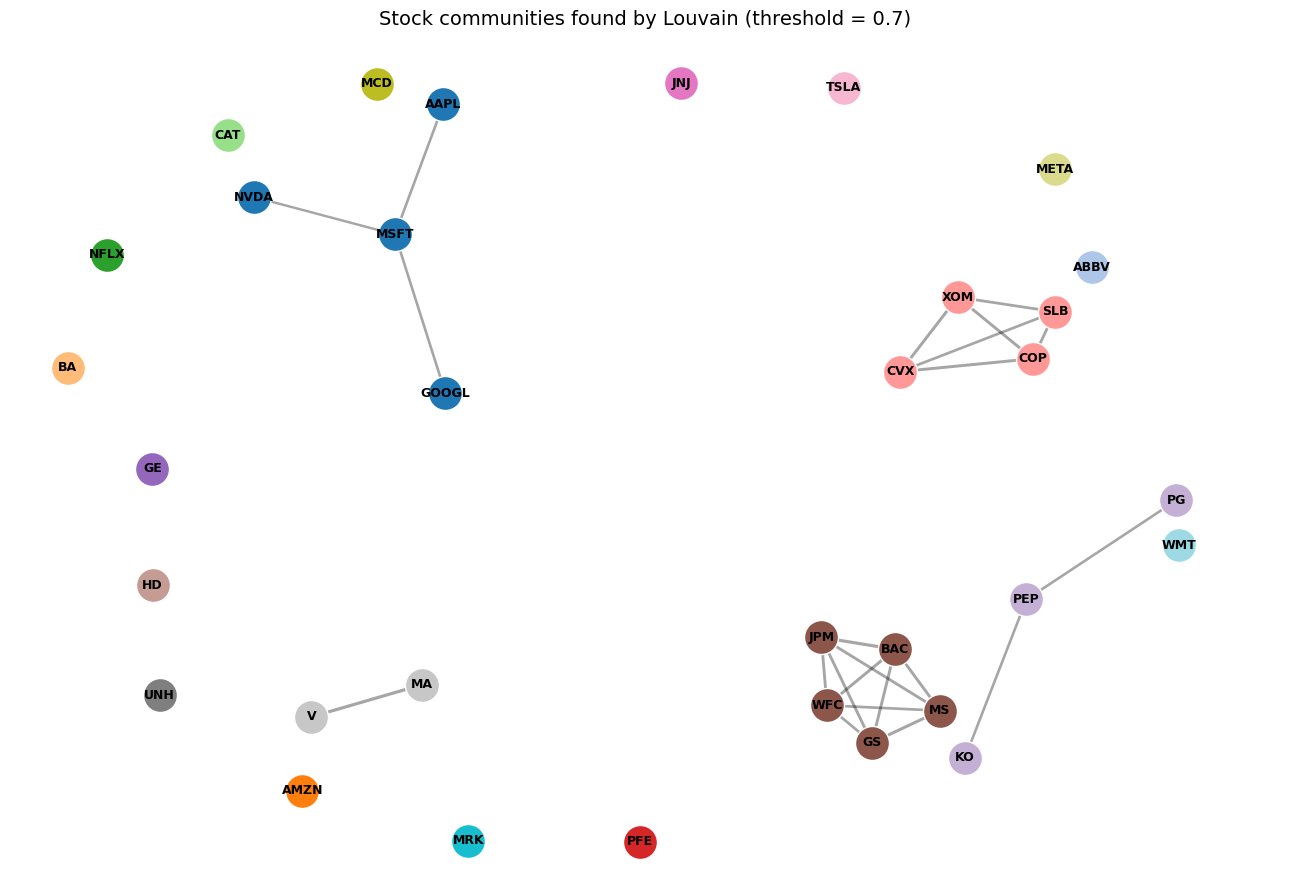

In [6]:
def draw_network(G, partition, threshold, filename=None):
    """Draw the network with one colour per community."""
    pos = nx.spring_layout(G, seed=SEED, k=0.5)
    com_ids = sorted(set(partition.values()))

    # tab20 instead of tab10, because we can easily end up with
    # more than 10 communities and colours would repeat.
    colours = {c: plt.cm.tab20(k % 20) for k, c in enumerate(com_ids)}

    plt.figure(figsize=(13, 9))

    widths = [G[u][v]["weight"] * 2.5 for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, alpha=0.35, width=widths)

    for c in com_ids:
        members = [n for n in G.nodes() if partition[n] == c]
        nx.draw_networkx_nodes(G, pos, members, node_size=600,
                               node_color=[colours[c]], edgecolors="white")

    nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

    plt.title("Stock communities found by Louvain (threshold = "
              + str(threshold) + ")", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


draw_network(G, partition, threshold,
             filename=os.path.join(FIGURE_DIR, "network_threshold_070.png"))

threshold 0.5 -> 151 edges, 4 communities, modularity 0.3457


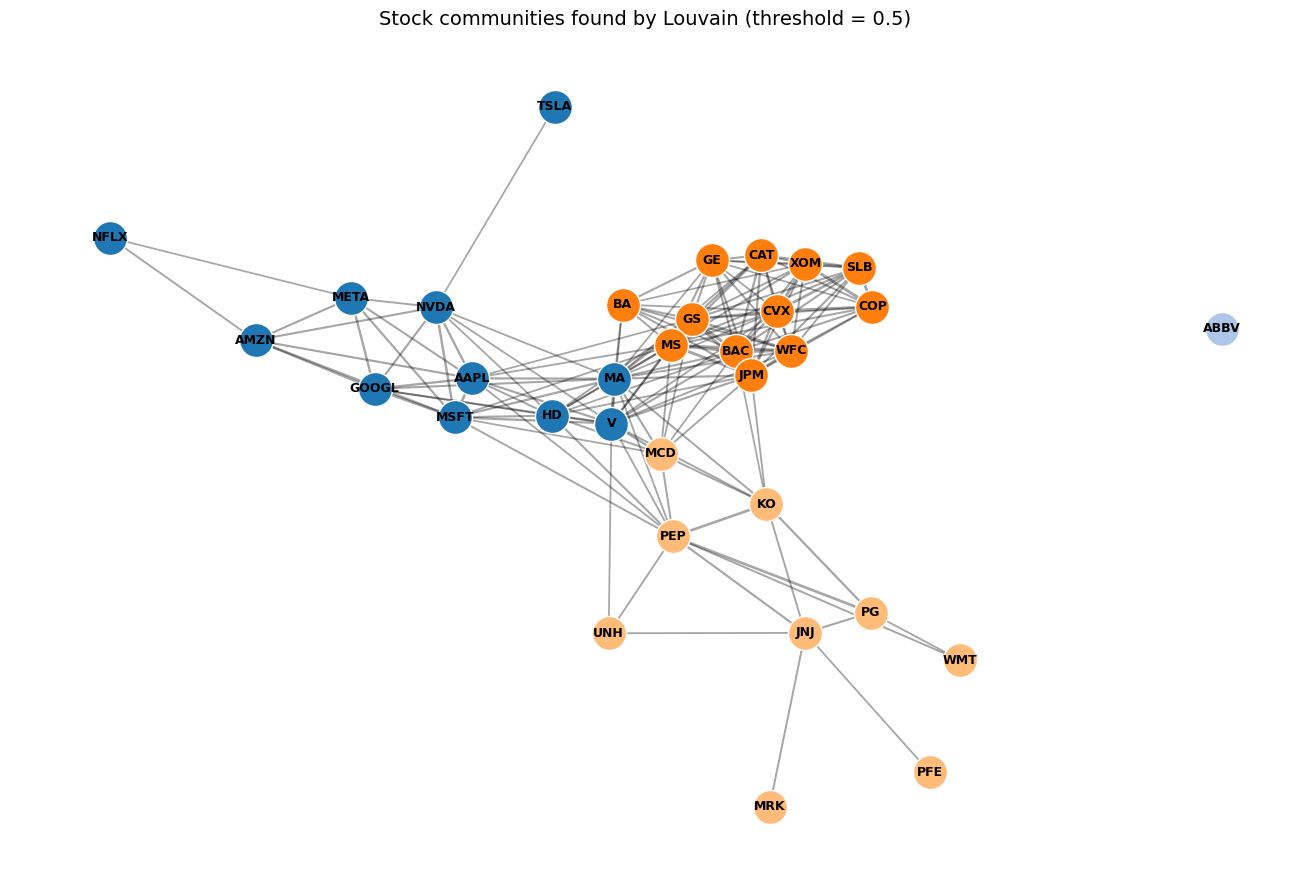

In [7]:
# Same thing at a lower threshold, so the difference is easy to see.
G_loose = build_graph(corr_matrix, 0.5)
partition_loose, modularity_loose = find_communities(G_loose)

print("threshold 0.5 ->", G_loose.number_of_edges(), "edges,",
      len(set(partition_loose.values())), "communities,",
      "modularity", round(modularity_loose, 4))

draw_network(G_loose, partition_loose, 0.5,
             filename=os.path.join(FIGURE_DIR, "network_threshold_050.png"))

## 4. How much does the choice of threshold matter?

The threshold of 0.7 was my own choice and nothing forced it. The resolution
parameter of Louvain is the same kind of free choice — it controls how large the
communities it looks for are. If the results flip around when I nudge these two
numbers, then they are not telling me much about the market.

So I sweep both and record what happens to the network and to the partition.

In [8]:
def summarize(corr, threshold, resolution=1.0, seed=SEED):
    """Build a network, find communities, and report a few numbers about it."""
    G = build_graph(corr, threshold)
    partition, modularity = find_communities(G, resolution, seed)
    sizes = pd.Series(partition).value_counts()

    return {
        "threshold": threshold,
        "resolution": resolution,
        "edges": G.number_of_edges(),
        "density": round(nx.density(G), 3),
        "communities": len(sizes),
        "singletons": int((sizes == 1).sum()),
        "largest": int(sizes.max()),
        "modularity": round(modularity, 4),
    }


thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
resolutions = [0.7, 1.0, 1.3]

rows = []
for t in thresholds:
    for r in resolutions:
        rows.append(summarize(corr_matrix, t, r))

experiment_table = pd.DataFrame(rows)
experiment_table

,threshold,resolution,edges,density,communities,singletons,largest,modularity
0,0.3,0.7,397,0.752,4,1,17,0.1096
1,0.3,1.0,397,0.752,3,0,12,0.1387
2,0.3,1.3,397,0.752,8,4,10,0.1091
3,0.4,0.7,267,0.506,3,0,15,0.2402
4,0.4,1.0,267,0.506,3,0,12,0.2515
5,0.4,1.3,267,0.506,5,2,12,0.2437
6,0.5,0.7,151,0.286,3,1,20,0.3246
7,0.5,1.0,151,0.286,4,1,12,0.3457
8,0.5,1.3,151,0.286,4,1,12,0.3423
9,0.6,0.7,62,0.117,13,8,7,0.4740


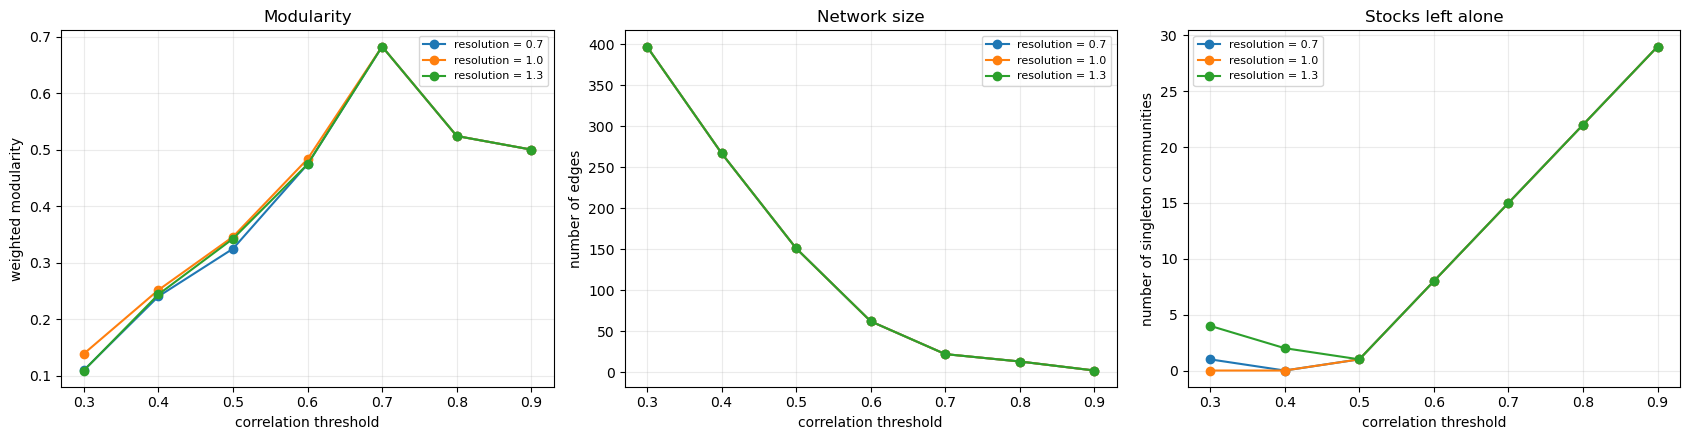

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for resolution, group in experiment_table.groupby("resolution"):
    axes[0].plot(group["threshold"], group["modularity"],
                 marker="o", label="resolution = " + str(resolution))
    axes[1].plot(group["threshold"], group["edges"],
                 marker="o", label="resolution = " + str(resolution))
    axes[2].plot(group["threshold"], group["singletons"],
                 marker="o", label="resolution = " + str(resolution))

axes[0].set_title("Modularity")
axes[0].set_ylabel("weighted modularity")

axes[1].set_title("Network size")
axes[1].set_ylabel("number of edges")

axes[2].set_title("Stocks left alone")
axes[2].set_ylabel("number of singleton communities")

for ax in axes:
    ax.set_xlabel("correlation threshold")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "threshold_sensitivity.png"),
            dpi=150, bbox_inches="tight")
plt.show()

The three panels together explain why the modularity number on its own is
misleading. Modularity climbs as the threshold goes up, but so does the number
of stocks left alone, while the number of edges collapses. The score is going up
precisely because the network is falling apart.

The resolution parameter barely changes anything, which is a good sign — the
grouping is driven by the data and not by that knob.

Somewhere around 0.5 looks like the useful compromise: enough edges that the
network is actually connected, but still selective enough that the edges mean
something. I use 0.5 for the centrality and sector sections below.

## 5. Pearson or Spearman?

Pearson correlation measures linear co-movement and a few extreme days can move
it quite a lot. Spearman works on ranks instead, so it picks up any monotonic
relationship and it is much less bothered by outliers.

Daily stock returns have plenty of extreme days, so it is worth checking whether
the structure survives the switch. If the two methods disagree, then whatever I
found is being driven by a handful of crash days.

In [10]:
correlation_methods = {
    "Pearson": returns.corr(method="pearson"),
    "Spearman": returns.corr(method="spearman"),
}

method_rows = []
for name, corr in correlation_methods.items():
    for t in thresholds:
        result = summarize(corr, t, resolution=1.0)
        result["method"] = name
        method_rows.append(result)

method_table = pd.DataFrame(method_rows)
print(method_table[["method", "threshold", "edges", "communities",
                    "singletons", "modularity"]].to_string(index=False))

  method  threshold  edges  communities  singletons  modularity
 Pearson        0.3    397            3           0      0.1387
 Pearson        0.4    267            3           0      0.2515
 Pearson        0.5    151            4           1      0.3457
 Pearson        0.6     62           12           8      0.4833
 Pearson        0.7     22           20          15      0.6824
 Pearson        0.8     13           25          22      0.5241
 Pearson        0.9      2           31          29      0.5000
Spearman        0.3    287            3           0      0.2907
Spearman        0.4    160            3           0      0.4329
Spearman        0.5     88            8           5      0.5283
Spearman        0.6     42           16          12      0.6227
Spearman        0.7     20           22          17      0.6405
Spearman        0.8     10           26          23      0.5458
Spearman        0.9      0           33          33      0.0000


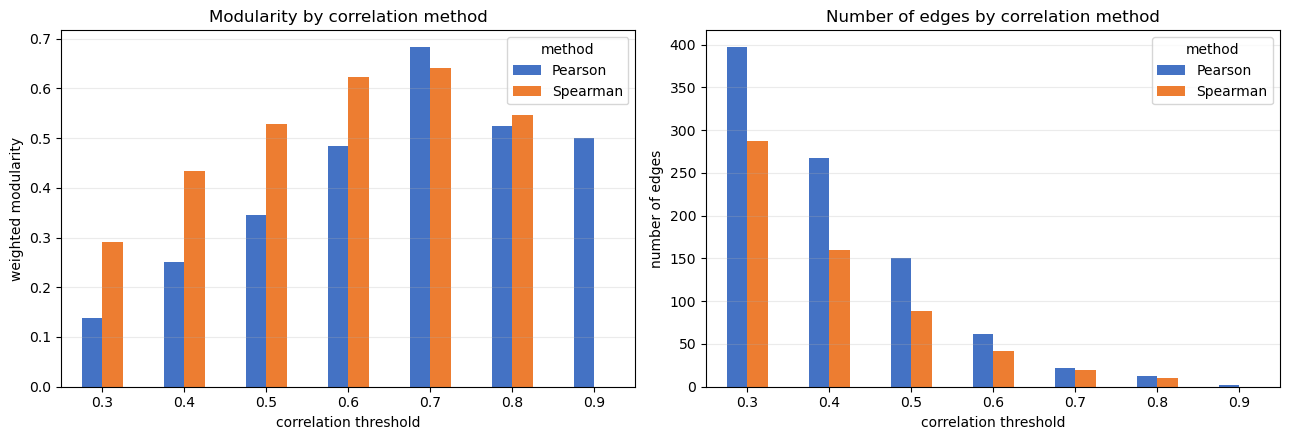

agreement between the two methods (Spearman rank corr of the pairs): 0.928


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

method_table.pivot(index="threshold", columns="method", values="modularity").plot(
    kind="bar", ax=axes[0], color=["#4472C4", "#ED7D31"])
axes[0].set_title("Modularity by correlation method")
axes[0].set_ylabel("weighted modularity")

method_table.pivot(index="threshold", columns="method", values="edges").plot(
    kind="bar", ax=axes[1], color=["#4472C4", "#ED7D31"])
axes[1].set_title("Number of edges by correlation method")
axes[1].set_ylabel("number of edges")

for ax in axes:
    ax.set_xlabel("correlation threshold")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "pearson_vs_spearman.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# Do the two methods actually rank the pairs the same way?
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
pearson_pairs = correlation_methods["Pearson"].where(mask).stack()
spearman_pairs = correlation_methods["Spearman"].where(mask).stack()
print("agreement between the two methods (Spearman rank corr of the pairs):",
      round(pearson_pairs.corr(spearman_pairs, method="spearman"), 3))

## 6. Which stocks sit at the centre?

Four different measures, because they answer different questions:

- **degree** — how many stocks does it move with?
- **weighted degree** — the same, but strong correlations count more
- **betweenness** — does it sit on the paths between different groups? A stock
  with high betweenness is a bridge between sectors
- **eigenvector** — is it connected to other well-connected stocks?

Eigenvector centrality needs a connected graph, so I compute it separately on
each connected component and then put the results back together.

I use the threshold of 0.5 network here. At 0.7 the graph is split into so many
pieces that betweenness is 0 almost everywhere and the numbers say nothing.

In [12]:
G_central = build_graph(corr_matrix, 0.5)

# Eigenvector centrality only works on a connected graph,
# so I run it on each component separately.
eigenvector = {}
for component in nx.connected_components(G_central):
    subgraph = G_central.subgraph(component)
    if subgraph.number_of_edges() == 0:
        for node in subgraph.nodes():
            eigenvector[node] = 0.0
    else:
        scores = nx.eigenvector_centrality(subgraph, max_iter=1000, weight="weight")
        eigenvector.update(scores)

centrality = pd.DataFrame({
    "degree": nx.degree_centrality(G_central),
    "weighted_degree": dict(G_central.degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(G_central, weight="weight"),
    "eigenvector": eigenvector,
})
centrality = centrality.sort_values("weighted_degree", ascending=False).round(3)

print("Most central stocks in the threshold 0.5 network:")
print(centrality.head(10).to_string())

Most central stocks in the threshold 0.5 network:
      degree  weighted_degree  betweenness  eigenvector
MS     0.531           10.981        0.010        0.311
MA     0.562           10.597        0.147        0.258
JPM    0.500           10.514        0.004        0.305
BAC    0.500           10.483        0.036        0.305
GS     0.500           10.223        0.038        0.299
V      0.531           10.124        0.141        0.236
WFC    0.406            8.357        0.008        0.264
CVX    0.406            8.283        0.006        0.255
XOM    0.344            7.051        0.000        0.219
MSFT   0.344            7.012        0.006        0.119


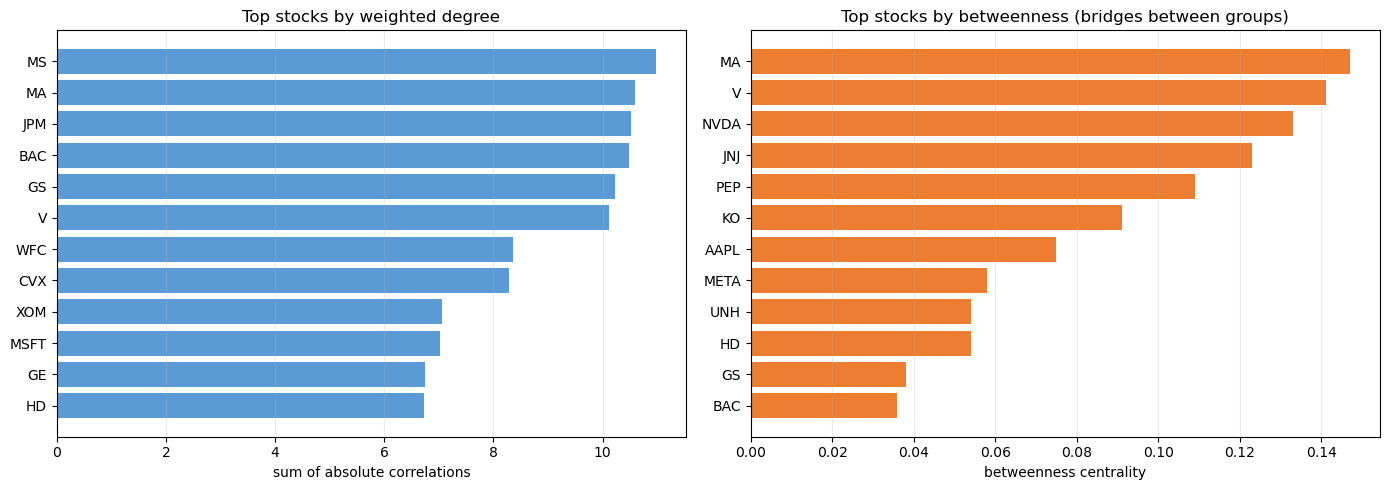

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_degree = centrality.head(12).sort_values("weighted_degree")
axes[0].barh(top_degree.index, top_degree["weighted_degree"], color="#5B9BD5")
axes[0].set_title("Top stocks by weighted degree")
axes[0].set_xlabel("sum of absolute correlations")

top_between = centrality.sort_values("betweenness", ascending=False).head(12)
top_between = top_between.sort_values("betweenness")
axes[1].barh(top_between.index, top_between["betweenness"], color="#ED7D31")
axes[1].set_title("Top stocks by betweenness (bridges between groups)")
axes[1].set_xlabel("betweenness centrality")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "centrality.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Do the communities match the real sectors?

Up to this point I have only been looking at the groups and saying "these look
like banks". That is an impression, not a result. Since I know which sector each
stock really belongs to, I can measure the agreement instead of eyeballing it.

Two standard scores:

- **ARI** (Adjusted Rand Index) — agreement between two partitions, corrected
  for the agreement you would get by chance. 0 means no better than random, 1
  means identical.
- **NMI** (Normalized Mutual Information) — how much knowing the community tells
  you about the sector, from 0 to 1.

The sector labels are the GICS sectors. Note that V and MA are classified under
Financials, which is where GICS moved the payment networks in 2023.

In [14]:
sectors = {
    'AAPL': 'Information Technology',
    'MSFT': 'Information Technology',
    'NVDA': 'Information Technology',
    'GOOGL': 'Communication Services',
    'META': 'Communication Services',
    'NFLX': 'Communication Services',
    'AMZN': 'Consumer Discretionary',
    'TSLA': 'Consumer Discretionary',
    'HD': 'Consumer Discretionary',
    'MCD': 'Consumer Discretionary',
    'JPM': 'Financials',
    'BAC': 'Financials',
    'WFC': 'Financials',
    'GS': 'Financials',
    'MS': 'Financials',
    'V': 'Financials',
    'MA': 'Financials',
    'JNJ': 'Health Care',
    'PFE': 'Health Care',
    'MRK': 'Health Care',
    'UNH': 'Health Care',
    'ABBV': 'Health Care',
    'XOM': 'Energy',
    'CVX': 'Energy',
    'COP': 'Energy',
    'SLB': 'Energy',
    'WMT': 'Consumer Staples',
    'PG': 'Consumer Staples',
    'KO': 'Consumer Staples',
    'PEP': 'Consumer Staples',
    'BA': 'Industrials',
    'CAT': 'Industrials',
    'GE': 'Industrials',
}

# Make sure I did not forget anyone.
missing = set(prices.columns) - set(sectors)
print("stocks without a sector label:", missing if missing else "none")
print("number of sectors:", len(set(sectors.values())))

stocks without a sector label: none
number of sectors: 8


In [15]:
def compare_to_sectors(corr, threshold, resolution=1.0, seed=SEED):
    """Score the Louvain partition against the real sector labels."""
    G = build_graph(corr, threshold)
    partition, modularity = find_communities(G, resolution, seed)

    stocks = sorted(partition.keys())
    found = [partition[s] for s in stocks]
    true = [sectors[s] for s in stocks]

    return {
        "threshold": threshold,
        "communities": len(set(found)),
        "modularity": round(modularity, 4),
        "ARI": round(adjusted_rand_score(true, found), 3),
        "NMI": round(normalized_mutual_info_score(true, found), 3),
    }


sector_rows = [compare_to_sectors(corr_matrix, t) for t in thresholds]
sector_table = pd.DataFrame(sector_rows)
print(sector_table.to_string(index=False))

best = sector_table.loc[sector_table["ARI"].idxmax()]
print()
print("Best agreement with the real sectors is at threshold",
      best["threshold"], "with ARI", best["ARI"], "and NMI", best["NMI"])

 threshold  communities  modularity   ARI   NMI
       0.3            3      0.1387 0.285 0.575
       0.4            3      0.2515 0.285 0.575
       0.5            4      0.3457 0.263 0.572
       0.6           12      0.4833 0.327 0.699
       0.7           20      0.6824 0.515 0.818
       0.8           25      0.5241 0.425 0.802
       0.9           31      0.5000 0.060 0.747

Best agreement with the real sectors is at threshold 0.7 with ARI 0.515 and NMI 0.818


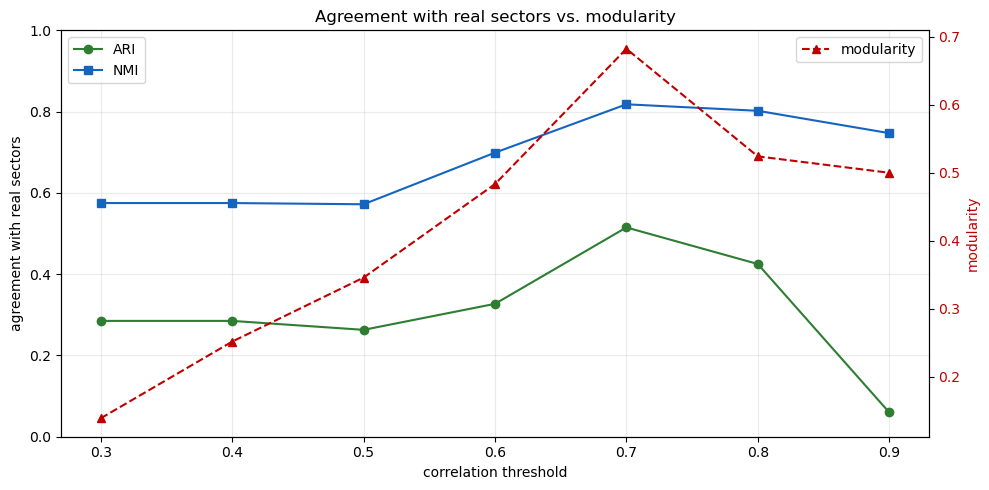

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(sector_table["threshold"], sector_table["ARI"],
         marker="o", color="#2E7D32", label="ARI")
ax1.plot(sector_table["threshold"], sector_table["NMI"],
         marker="s", color="#1565C0", label="NMI")
ax1.set_xlabel("correlation threshold")
ax1.set_ylabel("agreement with real sectors")
ax1.set_ylim(0, 1)
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(sector_table["threshold"], sector_table["modularity"],
         marker="^", color="#C00000", linestyle="--", label="modularity")
ax2.set_ylabel("modularity", color="#C00000")
ax2.tick_params(axis="y", labelcolor="#C00000")
ax2.legend(loc="upper right")

plt.title("Agreement with real sectors vs. modularity")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "sector_agreement.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# A closer look at the best threshold: which sector ended up in which community?
best_threshold = float(best["threshold"])
G_best = build_graph(corr_matrix, best_threshold)
partition_best, _ = find_communities(G_best)

crosstab = pd.crosstab(
    pd.Series({s: sectors[s] for s in partition_best}, name="sector"),
    pd.Series(partition_best, name="community"),
)

print("Sector against community at threshold", best_threshold)
print(crosstab.to_string())

Sector against community at threshold 0.7
community               0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19
sector                                                                                                
Communication Services   1   0   0   0   1   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0
Consumer Discretionary   0   0   1   0   0   0   0   0   0   0   0   1   0   1   0   0   1   0   0   0
Consumer Staples         0   0   0   0   0   0   0   0   0   3   0   0   0   0   0   0   0   0   0   1
Energy                   0   0   0   0   0   0   0   4   0   0   0   0   0   0   0   0   0   0   0   0
Financials               0   0   0   0   0   0   0   0   0   0   5   0   0   0   0   2   0   0   0   0
Health Care              0   1   0   0   0   0   1   0   0   0   0   0   1   0   1   0   0   0   1   0
Industrials              0   0   0   1   0   1   0   0   1   0   0   0   0   0   0   0   0   0   0   0
Information Technology   3   0 

## 8. Is the result stable, or did I just get a lucky seed?

Louvain is a greedy algorithm that walks through the nodes in a random order, so
different seeds can give different partitions. I fixed the seed at the top of
the notebook to keep things reproducible, but that hides the question of whether
the seed mattered in the first place.

So I run it 30 times with different seeds and look at the spread. I also compare
every run against the run with the seed I actually used, to see how much the
actual grouping moves around rather than just the score.

In [18]:
G_stability = build_graph(corr_matrix, 0.5)
reference_partition, _ = find_communities(G_stability, seed=SEED)
stocks = sorted(reference_partition.keys())
reference_labels = [reference_partition[s] for s in stocks]

seed_rows = []
for seed in range(30):
    partition_s, modularity_s = find_communities(G_stability, seed=seed)
    labels_s = [partition_s[s] for s in stocks]
    seed_rows.append({
        "seed": seed,
        "communities": len(set(labels_s)),
        "modularity": modularity_s,
        "ARI_vs_reference": adjusted_rand_score(reference_labels, labels_s),
    })

seed_table = pd.DataFrame(seed_rows)

print("Over 30 random seeds at threshold 0.5:")
print("  modularity:      mean", round(seed_table["modularity"].mean(), 4),
      " std", round(seed_table["modularity"].std(), 4),
      " min", round(seed_table["modularity"].min(), 4),
      " max", round(seed_table["modularity"].max(), 4))
print("  communities:     min", int(seed_table["communities"].min()),
      " max", int(seed_table["communities"].max()))
print("  ARI vs the seed I used: mean",
      round(seed_table["ARI_vs_reference"].mean(), 3),
      " min", round(seed_table["ARI_vs_reference"].min(), 3))
print()
print("Runs that found exactly the same partition:",
      int((seed_table["ARI_vs_reference"] > 0.999).sum()), "out of 30")

Over 30 random seeds at threshold 0.5:
  modularity:      mean 0.3457  std 0.0  min 0.3457  max 0.3457
  communities:     min 4  max 4
  ARI vs the seed I used: mean 1.0  min 1.0

Runs that found exactly the same partition: 30 out of 30


## 9. Does the structure hold over time?

One correlation matrix for five whole years averages over a lot of very
different market conditions. 2020 in particular was not a normal year — when
everything crashes at once, every stock correlates with every other stock, and
the sector structure should temporarily disappear into one big blob.

To check that, I slide a one-year window (252 trading days) through the data in
six-month steps and rebuild the network in each window.

In [19]:
window_size = 252   # roughly one trading year
step = 126          # roughly six months

rolling_rows = []
for start in range(0, len(returns) - window_size + 1, step):
    window = returns.iloc[start:start + window_size]
    window_corr = window.corr()

    result = summarize(window_corr, 0.5, resolution=1.0)
    scores = compare_to_sectors(window_corr, 0.5)

    result["window_start"] = window.index[0].date()
    result["window_end"] = window.index[-1].date()
    result["mean_correlation"] = round(
        window_corr.where(np.triu(np.ones(window_corr.shape), k=1).astype(bool))
        .stack().mean(), 3)
    result["ARI"] = scores["ARI"]
    rolling_rows.append(result)

rolling_table = pd.DataFrame(rolling_rows)
print(rolling_table[["window_start", "window_end", "mean_correlation", "edges",
                     "communities", "modularity", "ARI"]].to_string(index=False))

window_start window_end  mean_correlation  edges  communities  modularity   ARI
  2019-01-03 2020-01-02             0.304     61           14      0.4540 0.272
  2019-07-05 2020-07-02             0.603    405            3      0.0726 0.216
  2020-01-03 2020-12-31             0.564    352            2      0.1357 0.185
  2020-07-06 2021-07-02             0.269     89            9      0.4423 0.300
  2021-01-04 2021-12-31             0.241     76           12      0.4057 0.260
  2021-07-06 2022-07-05             0.328    101            7      0.5156 0.472
  2022-01-03 2023-01-03             0.393    155            5      0.3128 0.494
  2022-07-06 2023-07-06             0.357     95            6      0.4499 0.456


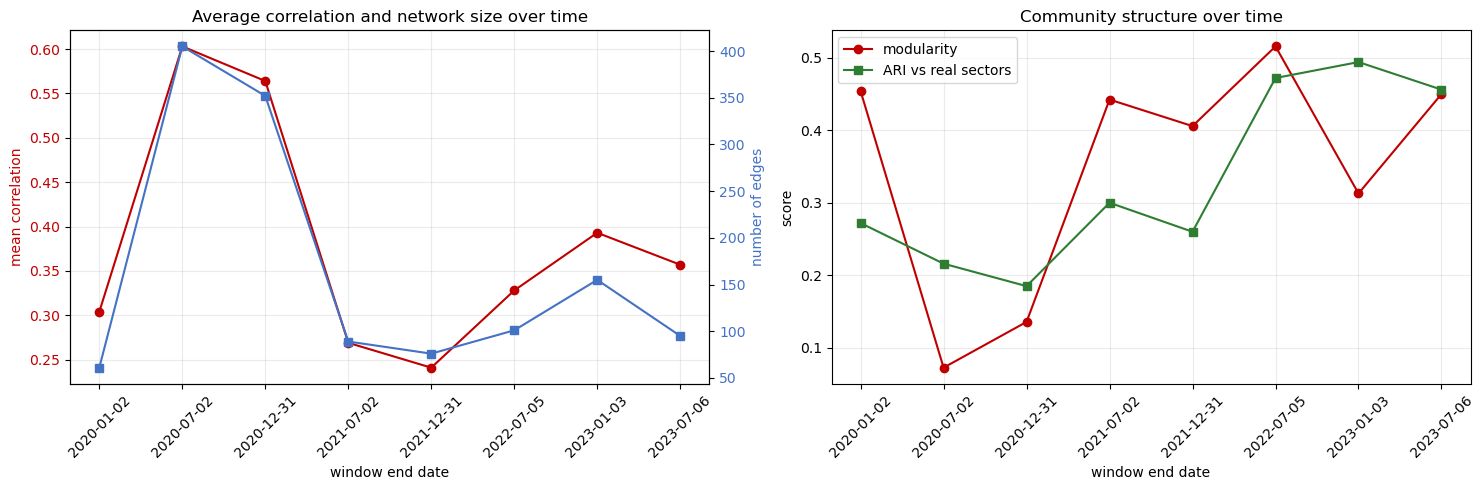

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = rolling_table["window_end"].astype(str)

ax1 = axes[0]
ax1.plot(x, rolling_table["mean_correlation"], marker="o", color="#C00000")
ax1.set_ylabel("mean correlation", color="#C00000")
ax1.tick_params(axis="y", labelcolor="#C00000")
ax1.set_title("Average correlation and network size over time")
ax1.grid(alpha=0.25)

ax1b = ax1.twinx()
ax1b.plot(x, rolling_table["edges"], marker="s", color="#4472C4")
ax1b.set_ylabel("number of edges", color="#4472C4")
ax1b.tick_params(axis="y", labelcolor="#4472C4")

ax2 = axes[1]
ax2.plot(x, rolling_table["modularity"], marker="o",
         color="#C00000", label="modularity")
ax2.plot(x, rolling_table["ARI"], marker="s",
         color="#2E7D32", label="ARI vs real sectors")
ax2.set_ylabel("score")
ax2.set_title("Community structure over time")
ax2.legend()
ax2.grid(alpha=0.25)

for ax in (ax1, ax2):
    ax.set_xlabel("window end date")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "rolling_stability.png"),
            dpi=150, bbox_inches="tight")
plt.show()